# Data Exploration and Analysis

In [1]:
import matplotlib.pyplot as plt
import iml_assignment as iml 
import pandas as pd

pd.set_option('display.max_columns', 30)

In [2]:
train_df = iml.load_data("train")
test_df = iml.load_data("test")

summary = iml.get_dataset_summary(train_df,test_df)
display(summary)

print("Time-major ordering verified:", iml.verify_column_ordering(train_df))


,Property,Training Set,Test Set (Kaggle)
0,Total Samples (Rows),679,403
1,Total Columns,5752,5751
2,Sensor Signal Columns,5750,5750
3,Timesteps per Window,250,250
4,Sensor Channels,23,23
5,Window Duration (sec),5.0s,5.0s
6,Sampling Rate (Hz),50 Hz,50 Hz
7,Target Column Present,True,False
8,Target Classes Count,12,Hidden (Evaluation)


Time-major ordering verified: True


,Activity,Count,Percentage (%)
0,standing,59,8.69
1,sitting,59,8.69
2,lying,66,9.72
3,walking,63,9.28
4,climbing_stairs,56,8.25
5,waist_bends,53,7.81
6,arm_elevation,55,8.10
7,knees_bending,55,8.10
8,cycling,67,9.87
9,jogging,66,9.72


Figure saved to: D:\Projects\IML_Assignment\reports\figures\fig1_class_distribution.png


[]

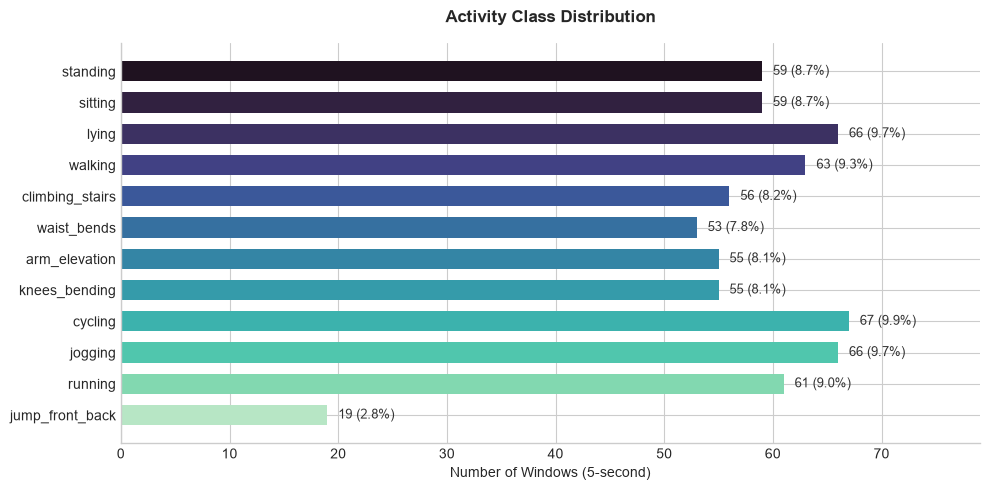

In [3]:
dist_df = iml.get_class_distribution(train_df)
display(dist_df)

fig, ax = iml.plot_class_distribution(train_df, save_name="fig1_class_distribution.png")
plt.plot()


Total cells corrupted: 687583 (17.61%)
  - Standard NaNs: 516835 (13.24%)
  - 9999.0 Sentinels: 170748 (4.37%)
Figure saved to: D:\Projects\IML_Assignment\reports\figures\fig2_corruption_by_channel.png


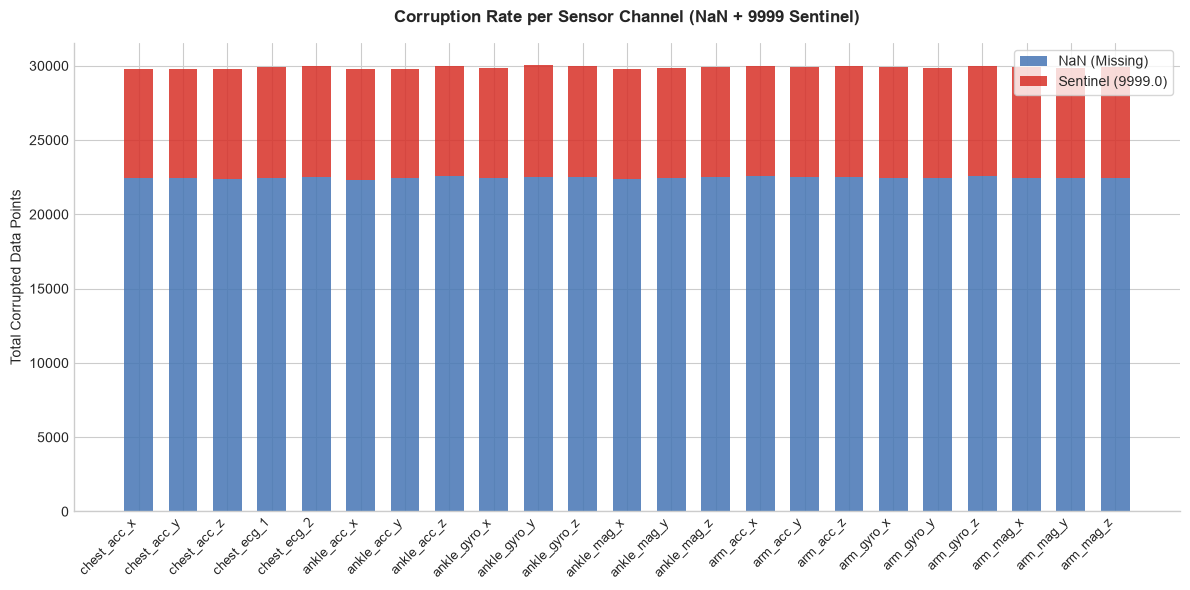

In [4]:
#missing values

missing_info = iml.analyze_missing_and_sentinels(train_df)

print(f"Total cells corrupted: {missing_info['total_corrupt_count']} ({missing_info['total_corrupt_percentage']}%)")
print(f"  - Standard NaNs: {missing_info['nan_count']} ({missing_info['nan_percentage']}%)")
print(f"  - 9999.0 Sentinels: {missing_info['sentinel_count']} ({missing_info['sentinel_percentage']}%)")

 # Plot corruption by sensor channel
fig, ax = iml.plot_missingness_by_channel(missing_info["channel_summary"], save_name="fig2_corruption_by_channel.png")
plt.show()

Figure saved to: D:\Projects\IML_Assignment\reports\figures\fig3_raw_vs_cleaned.png


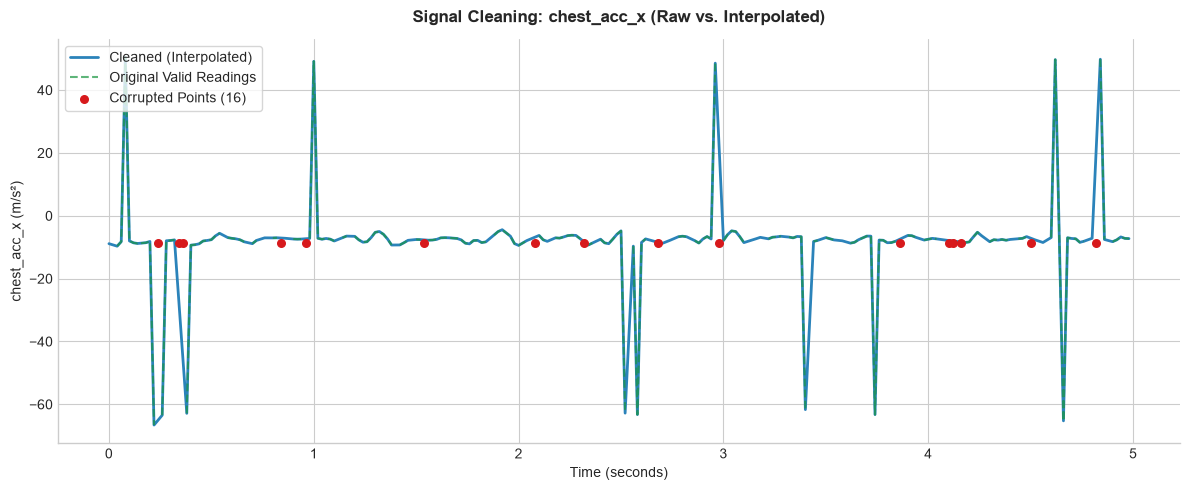

Figure saved to: D:\Projects\IML_Assignment\reports\figures\fig4_multichannel_waveform.png


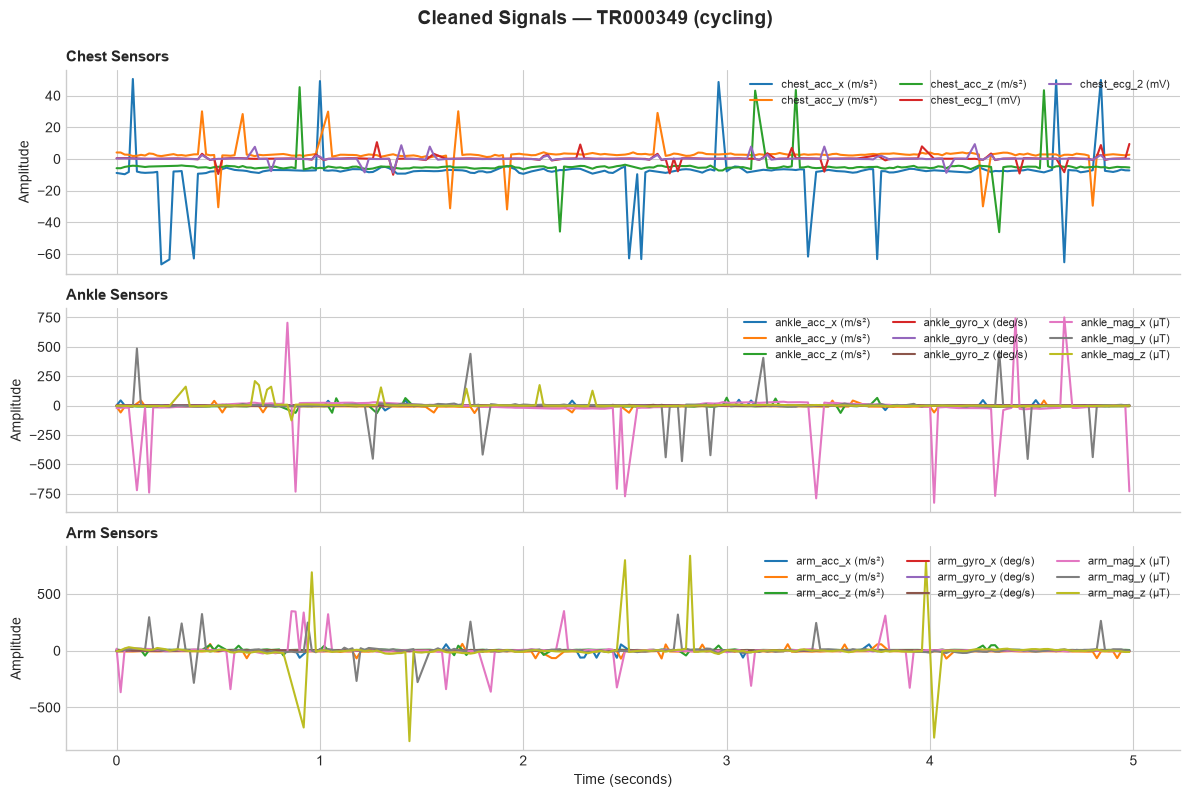

In [5]:
# Extract sample 0 (cycling)
raw_wave, label = iml.extract_sample_waveform(train_df, 0)
clean_wave = iml.clean_sample_waveform(raw_wave)

# Plot raw vs cleaned for chest accelerometer X
fig, ax = iml.plot_raw_vs_cleaned(raw_wave, clean_wave, channel="chest_acc_x", save_name="fig3_raw_vs_cleaned.png")
plt.show()

# Multi-channel 3-panel waveform plot (Chest, Ankle, Arm)
fig, axes = iml.plot_sample_waveforms(clean_wave, title=f"Cleaned Signals — {label}", save_name="fig4_multichannel_waveform.png")
plt.show()

Figure saved to: D:\Projects\IML_Assignment\reports\figures\fig5_walking_vs_running.png


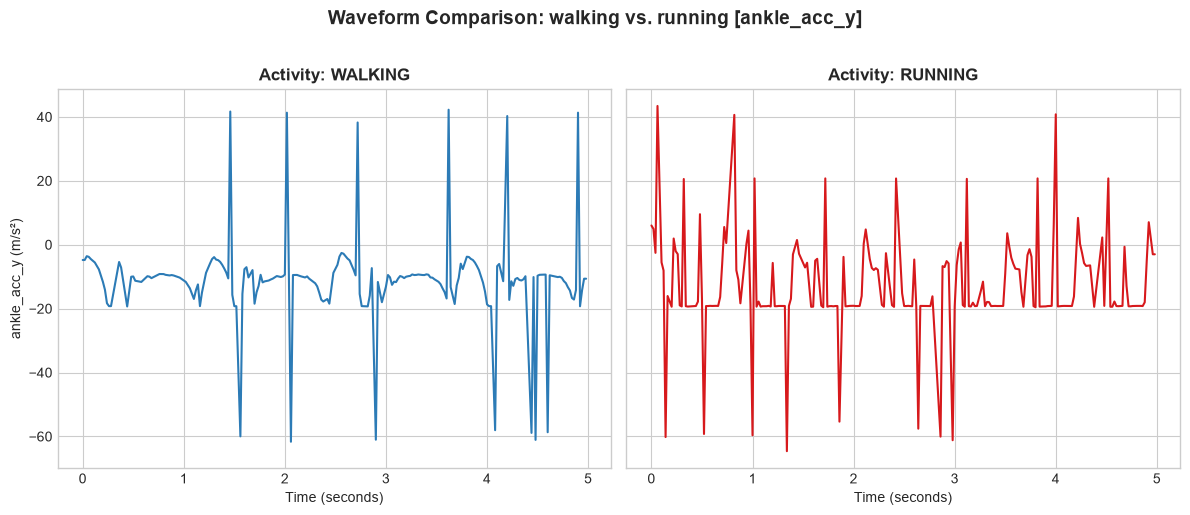

In [6]:
fig, axes = iml.plot_activity_comparison(
train_df,
activity_a="walking",
activity_b="running",
channel="ankle_acc_y",
save_name="fig5_walking_vs_running.png"
)
plt.show()

Figure saved to: D:\Projects\IML_Assignment\reports\figures\fig6_sensor_correlations.png


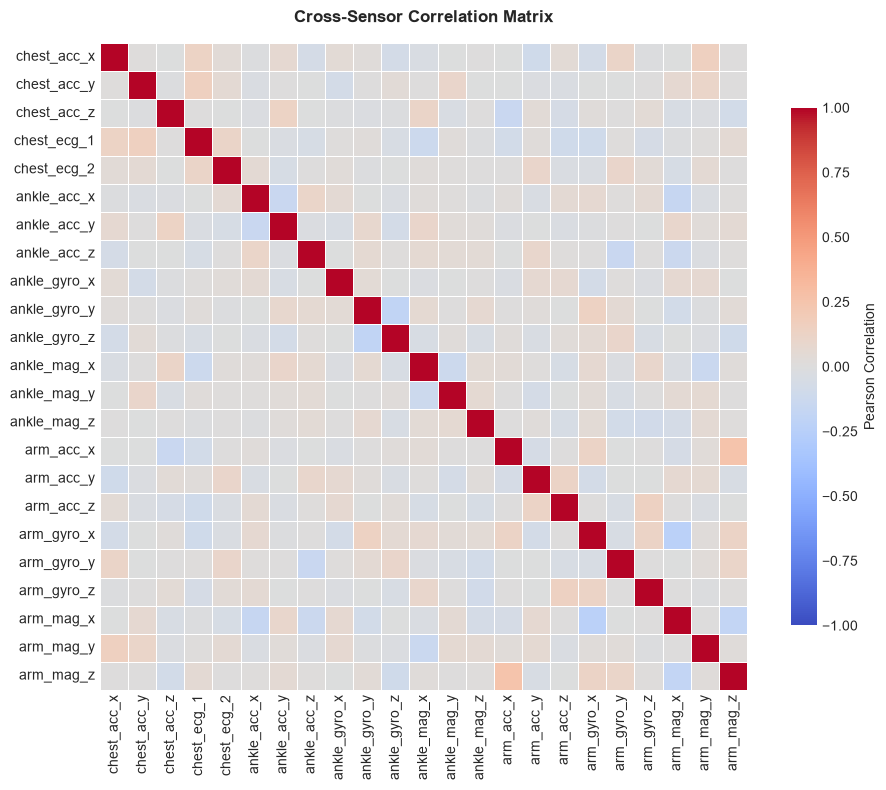

Figure saved to: D:\Projects\IML_Assignment\reports\figures\fig7_psd_ankle.png


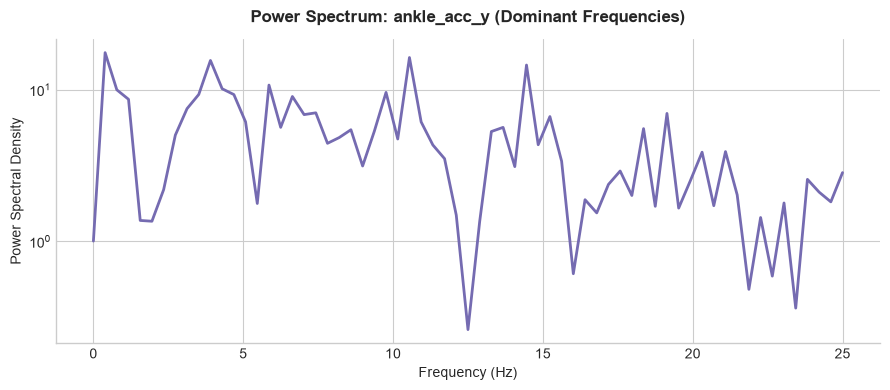

In [7]:
# 23-sensor correlation heatmap
fig, ax = iml.plot_sensor_correlations(raw_wave, save_name="fig6_sensor_correlations.png")
plt.show()

# Power spectrum showing cadence/step frequency
fig, ax = iml.plot_frequency_spectrum(clean_wave, channel="ankle_acc_y", save_name="fig7_psd_ankle.png")
plt.show()

In [8]:
stats_df = iml.compute_channel_statistics(train_df, clean=True)
display(stats_df)

,Channel,Min,Max,Mean,Std,Median
0,chest_acc_x,-67.0101,52.0094,-7.4131,13.8261,-8.7319
1,chest_acc_y,-33.6870,33.3260,-0.1311,7.3245,-0.5549
2,chest_acc_z,-48.1111,46.0819,-1.0462,11.0455,-1.1597
3,chest_ecg_1,-10.5677,10.5758,-0.0001,2.1545,-0.0712
4,chest_ecg_2,-10.2726,10.1344,-0.0209,2.0206,-0.0586
5,ankle_acc_x,-47.9096,51.5179,2.0177,10.3093,1.4858
6,ankle_acc_y,-66.3517,48.4924,-9.0912,12.5555,-9.5883
7,ankle_acc_z,-70.2701,69.3823,-0.3815,15.5039,0.3990
8,ankle_gyro_x,-4.0772,4.3980,0.1584,1.0143,0.2467
9,ankle_gyro_y,-5.0813,4.0760,-0.5187,1.0810,-0.6342
